# ERA5: conditional forecasts and backcasts of air-parcel tracks with a Kinematic Interpolant

A self-contained run from reanalysis winds to forecasts, in the layout of the ocean notebook of the Kinematic Interpolant paper (Jiang, Marzouk, Bose & Pooladian, *Learning smooth dynamics via Kinematic Interpolants*, arXiv:2610.22519; `ki/notebooks/oceans_currents_interpolant.ipynb`). Steps:

1. download three days of hourly ERA5 winds (0.25°, 37 pressure levels) from Google's public ARCO store;
2. write them as LAGRANTO input files;
3. release patches of air parcels and compute their 3-D tracks with LAGRANTO (the *true tracks*);
4. turn the tracks into hourly positions, velocities and accelerations;
5. load the conditional Kinematic Interpolant trained on 2015–2017 (public Hugging Face model);
6. **forecast**: from the tracks of 192 parcels of a patch over the 48 h before an anchor time, integrate other parcels of the patch 24 h forward; **backcast**: from the 48 h after the anchor, integrate them 24 h backward; deterministically and as a 16-member ensemble;
7. compare with the true tracks and with straight motion.

The model never sees a wind field. Case: the Pacific Northwest heat dome of late June 2021 (2021 was not used in training). Running it downloads about 34 GB (a few minutes at 150 MB/s) into `data/notebook/`, which is deleted at the end; LAGRANTO must be built (`bash ../lagranto/build.sh`).

## 1. Imports and settings

In [1]:
from pathlib import Path
import json, math, os, shutil, subprocess, sys, time
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy.interpolate import CubicSpline, RegularGridInterpolator
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scripts/ctx_model.py').is_file() and (p / 'PLAN.md').is_file())
LAGRANTO = ROOT.parent / 'lagranto'
sys.path.insert(0, str(LAGRANTO / 'python'))
import lagranto_io as lio

RELEASE = np.datetime64('2021-06-24T00', 'h')   # parcels released here; the window is 72 h
WINDOW_H = 72
CENTRES = [(52.0, 232.0), (56.0, 240.0), (48.0, 226.0), (60.0, 248.0)]   # patch centres (deg N, deg E) around the ridge
SIGMAS = [0.477, 0.285]                      # start levels: pressure / surface pressure
N_PER, RADIUS_KM = 480, 300.0                # parcels per patch, disk radius (as in training)
WORK = ROOT / 'data/notebook'                # downloaded winds and LAGRANTO files (deleted at the end)
MODEL_REPO = 'yanxingjianken/ki-era5-tracks'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
H_KM, A_KM = 7.0, 6371.0
WORK.mkdir(parents=True, exist_ok=True)
print('device', DEVICE)

device cuda


## 2. ERA5 winds as LAGRANTO input files
One file per hour with u, v, the pressure vertical velocity omega (Pa/s) and the surface pressure on the 37 pressure levels. On pure pressure levels LAGRANTO's reader ignores the surface pressure and puts the ground at 1000 hPa everywhere; `write_pfile_plev` therefore gives the bottom level a tiny surface-pressure weight (bk = 0.002), which makes LAGRANTO keep parcels above the terrain. Each variable-hour of the store is one global chunk of 154 MB, so the whole globe is downloaded.

In [2]:
import gcsfs, xarray as xr
store = xr.open_zarr(gcsfs.GCSFileSystem(token='anon').get_mapper('gcp-public-data-arco-era5/ar/full_37-1h-0p25deg-chunk-1.zarr-v3'), chunks=None)
VARS = {'U': 'u_component_of_wind', 'V': 'v_component_of_wind', 'OMEGA': 'vertical_velocity', 'PS': 'surface_pressure'}
HOURS = RELEASE + np.arange(WINDOW_H + 1) * np.timedelta64(1, 'h')
t0 = time.time()
for t in HOURS:
    if (WORK / lio._pname(t)).exists():
        continue
    f = {k: store[v].sel(time=t).values for k, v in VARS.items()}
    lio.write_pfile_plev(WORK, t, store.longitude.values, store.latitude.values, store.level.values, f['U'], f['V'], f['OMEGA'], f['PS'])
z500 = store['geopotential'].sel(time=[RELEASE + np.timedelta64(h, 'h') for h in (24, 48, 72)], level=500).isel(latitude=slice(None, None, 4), longitude=slice(None, None, 4)) / 9.80665
z500 = z500.load()
print(f'{len(HOURS)} hourly files from {HOURS[0]} to {HOURS[-1]} in {time.time() - t0:.0f} s')

73 hourly files from 2021-06-24T00 to 2021-06-27T00 in 904 s


## 3. True tracks with LAGRANTO
Each patch is 480 parcels uniform in a disk of 300 km radius at one start level, the start pressure being sigma times the local surface pressure (as in training). caltra integrates the 3-D tracks with a 1-minute step and writes positions every 10 minutes; `-j` lifts parcels that touch the ground back into the air.

In [3]:
def destination(lat, lon, bearing, dist_km):
    p1, l1, d = np.deg2rad(lat), np.deg2rad(lon), dist_km / A_KM
    p2 = np.arcsin(np.sin(p1) * np.cos(d) + np.cos(p1) * np.sin(d) * np.cos(bearing))
    l2 = l1 + np.arctan2(np.sin(bearing) * np.sin(d) * np.cos(p1), np.cos(d) - np.sin(p1) * np.sin(p2))
    return np.rad2deg(p2), np.rad2deg(l2) % 360.0

import netCDF4
with netCDF4.Dataset(WORK / lio._pname(RELEASE)) as nc:
    ps0 = np.asarray(nc['PS'][0, 0], float); box = (nc['PS'].xmin, nc['PS'].xmax, nc['PS'].ymin, nc['PS'].ymax)
ps_at = RegularGridInterpolator((np.linspace(box[2], box[3], ps0.shape[0]), np.linspace(box[0], box[1], ps0.shape[1])), ps0)
rng = np.random.default_rng(0)
lat, lon, pres, lev, pid = [], [], [], [], []
for k, sigma in enumerate(SIGMAS):
    for q, (clat, clon) in enumerate(CENTRES):
        la, lo = destination(clat, clon, rng.uniform(0, 2 * np.pi, N_PER), RADIUS_KM * np.sqrt(rng.uniform(0, 1, N_PER)))
        lat.append(la); lon.append(lo); pres.append(sigma * ps_at(np.c_[la, lo])); lev.append(np.full(N_PER, k)); pid.append(np.full(N_PER, q))
lat, lon, pres, lev, pid = map(np.concatenate, (lat, lon, pres, lev, pid))
lio.startfile(WORK / 'startf', lon, lat, pres, lon_min=0.0)
env = dict(os.environ, LAGRANTO=str(LAGRANTO), PATH=f"{LAGRANTO / 'bin'}:{os.environ['PATH']}")
t0 = time.time()
out = subprocess.run(['caltra', lio._pname(HOURS[0])[1:], lio._pname(HOURS[-1])[1:], 'startf', 'traj.3', '-i', '1', '-t', '1', '-o', '10', '-j'],
                     cwd=WORK, env=env, capture_output=True, text=True)
assert out.returncode == 0, out.stdout[-2000:]
tr = lio.read_traj(WORK / 'traj.3')
print(f"{tr['lon'].shape[1]} tracks, {len(tr['time'])} times in {time.time() - t0:.0f} s; incomplete: {int((~np.isfinite(tr['lon'])).any(0).sum())}")

3840 tracks, 433 times in 184 s; incomplete: 0


## 4. Hourly positions, velocities and accelerations
Positions in north-polar stereographic x, y (km) and log-pressure height z = −7 km ln(p / 1000 hPa); a cubic spline through the 10-minute positions gives hourly velocity and acceleration (as in training).

In [4]:
def lonlat_to_xy(lon, lat):
    r = 2 * A_KM * np.tan(np.deg2rad(90.0 - lat) / 2); lam = np.deg2rad(lon)
    return np.stack([r * np.sin(lam), -r * np.cos(lam)], -1)

def xy_to_lonlat(x):
    r = np.hypot(x[..., 0], x[..., 1])
    return np.rad2deg(np.arctan2(x[..., 0], -x[..., 1])) % 360.0, 90.0 - np.rad2deg(2 * np.arctan(r / (2 * A_KM)))

t = tr['time'] - tr['time'][0]
lam = np.rad2deg(np.unwrap(np.deg2rad(tr['lon']), axis=0))
xyz = np.concatenate([lonlat_to_xy(lam, tr['lat']), (-H_KM * np.log(tr['p'] / 1000.0))[..., None]], -1)
spl = CubicSpline(t, xyz, axis=0)
th = np.arange(WINDOW_H + 1.0)
X, V, A = spl(th).astype(np.float32), spl(th, 1).astype(np.float32), spl(th, 2).astype(np.float32)   # (73 h, parcels, 3)
P_HPA = 1000.0 * np.exp(-X[..., 2] / H_KM)
print(X.shape, f'median horizontal speed {np.median(np.hypot(V[..., 0], V[..., 1])):.0f} km/h')

(73, 3840, 3) median horizontal speed 72 km/h


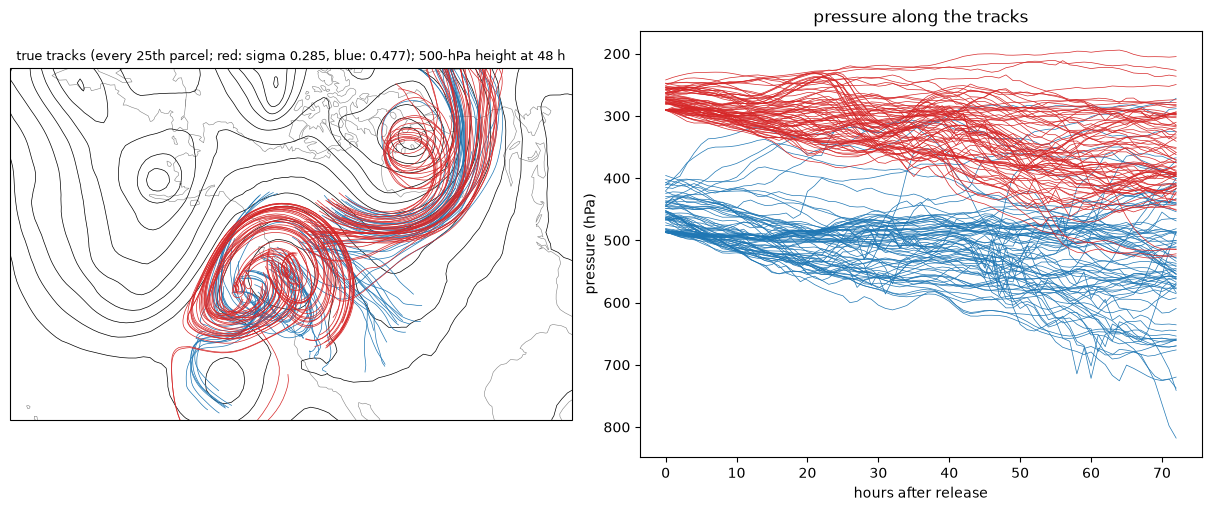

In [5]:
fig = plt.figure(figsize=(12, 5), layout='constrained')
ax = fig.add_subplot(1, 2, 1, projection=ccrs.NorthPolarStereo(central_longitude=235))
ax.set_extent([190, 280, 30, 80], ccrs.PlateCarree()); ax.coastlines(lw=0.4, color='0.5')
ax.contour(z500.longitude, z500.latitude, z500.isel(time=1), levels=np.arange(5200, 6000, 60), colors='k', linewidths=0.5, transform=ccrs.PlateCarree())
lo, la = xy_to_lonlat(X)
for i in range(0, X.shape[1], 25):
    ax.plot(np.rad2deg(np.unwrap(np.deg2rad(lo[:, i]))), la[:, i], lw=0.5, color='tab:red' if lev[i] == 1 else 'tab:blue', transform=ccrs.Geodetic())
ax.set_title('true tracks (every 25th parcel; red: sigma 0.285, blue: 0.477); 500-hPa height at 48 h', fontsize=9)
b = fig.add_subplot(1, 2, 2)
for i in range(0, X.shape[1], 25):
    b.plot(th, P_HPA[:, i], lw=0.5, color='tab:red' if lev[i] == 1 else 'tab:blue')
b.invert_yaxis(); b.set(xlabel='hours after release', ylabel='pressure (hPa)', title='pressure along the tracks')
plt.show()

## 5. The conditional Kinematic Interpolant
A parcel's state is its position (x, y, z) and velocity. Context tokens are the observed parcels of the patch every 3 h over 48 h: time from the anchor, position relative to the patch centroid at the anchor (absolute height), sin(latitude) and velocity, each axis divided by its scale. A Perceiver encoder compresses them into 96 latent vectors; a query state reads the latents by cross-attention and returns the acceleration and the scaled velocity score of the paper (code copied from `scripts/ctx_model.py`). The weights and the per-axis scales are downloaded from the public Hugging Face model.

In [6]:
N_FEAT = 8   # token and query features: time, x, y, z, sin(latitude), u, v, w


class Fourier(nn.Module):
    """Raw features plus sin/cos of the first `n_fourier` features at octave frequencies."""

    def __init__(self, n_in, n_fourier, octaves=6):
        super().__init__()
        self.n_fourier = n_fourier
        self.register_buffer("freqs", math.pi * 2.0 ** torch.arange(octaves, dtype=torch.float32))
        self.n_out = n_in + 2 * n_fourier * octaves

    def forward(self, z):
        f = z[..., : self.n_fourier, None] * self.freqs
        return torch.cat([z, torch.sin(f).flatten(-2), torch.cos(f).flatten(-2)], dim=-1)


class Block(nn.Module):
    """Pre-norm attention block (cross-attention when a context is given) with an MLP."""

    def __init__(self, d, heads, cross=False):
        super().__init__()
        self.nq = nn.LayerNorm(d)
        self.nk = nn.LayerNorm(d) if cross else None
        self.attn = nn.MultiheadAttention(d, heads, batch_first=True)
        self.mlp = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, q, kv=None, pad=None):
        h = self.nq(q)
        k = h if kv is None else self.nk(kv)
        q = q + self.attn(h, k, k, key_padding_mask=pad, need_weights=False)[0]
        return q + self.mlp(q)


def embed(n_in, n_fourier, d):
    f = Fourier(n_in, n_fourier)
    return nn.Sequential(f, nn.Linear(f.n_out, d), nn.GELU(), nn.Linear(d, d))


class ContextKI(nn.Module):
    """Perceiver encoder over context tokens and a cross-attention decoder for query states.

    Token features: (tau, x, y, z, sin lat, u, v, w); query features: the same for the state to be advanced.
    """

    def __init__(self, d=384, heads=8, latents=96, enc_layers=6, dec_layers=3):
        super().__init__()
        self.tok, self.qry = embed(N_FEAT, 4, d), embed(N_FEAT, 4, d)
        self.latents = nn.Parameter(torch.randn(latents, d) * 0.02)
        self.read = Block(d, heads, cross=True)
        self.enc = nn.ModuleList([Block(d, heads) for _ in range(enc_layers)])
        self.dec = nn.ModuleList([Block(d, heads, cross=True) for _ in range(dec_layers)])
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 6))
        nn.init.zeros_(self.head[1].weight)
        nn.init.zeros_(self.head[1].bias)

    def encode(self, tokens, pad=None):
        """tokens (B, M, 8), pad (B, M) True where absent -> latents (B, L, d)."""
        z = self.latents.expand(tokens.shape[0], -1, -1)
        z = self.read(z, self.tok(tokens), pad)
        for blk in self.enc:
            z = blk(z)
        return z

    def decode(self, z, queries):
        """queries (B, Q, 8) -> acceleration (B, Q, 3) and scaled score (B, Q, 3)."""
        h = self.qry(queries)
        for blk in self.dec:
            h = blk(h, z)
        out = self.head(h)
        return out[..., :3], out[..., 3:]

    def forward(self, tokens, pad, queries):
        return self.decode(self.encode(tokens, pad), queries)

In [7]:
import warnings
warnings.filterwarnings('ignore', message='IProgress not found')   # progress bars without ipywidgets
from huggingface_hub import hf_hub_download
ck = torch.load(hf_hub_download(MODEL_REPO, 'context_ki_era5.pt'), map_location=DEVICE, weights_only=False)
ens = json.loads(Path(hf_hub_download(MODEL_REPO, 'ensemble.json')).read_text())
model = ContextKI(d=ck['args']['d_model']).to(DEVICE).eval(); model.load_state_dict(ck['state'])
SC = ck['scales']; tt = lambda v: torch.tensor(v, dtype=torch.float32, device=DEVICE)
POS, VEL, ACC, TIME_H = tt(SC['pos_km']), tt(SC['vel_kmh']), tt(SC['acc_kmh2']), float(SC['time_h'])
SIGMA_V = tt([5.0, 5.0, 0.01]) * float(np.pi * np.sqrt(3) / 6.0)   # training noise in velocity (km/h)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters; scales {SC['vel_kmh']} km/h, {SC['acc_kmh2']} km/h2; ensemble eps_rel {ens['eps_rel']}")

32.2 M parameters; scales [62.02, 60.74, 0.08518] km/h, [5.366, 5.411, 0.1245] km/h2; ensemble eps_rel 1.5


## 6. Forecasts and backcasts
**Forecast** at anchor 48 h: the context is 192 parcels of the patch observed every 3 h over 0–48 h; 64 other parcels start from their true state at 48 h and are integrated to 72 h. **Backcast** at anchor 24 h: the context is observed over 24–72 h; the parcels are integrated backward to 0 h. Deterministic tracks follow x' = v, v' = a (Heun, 10-minute steps); ensemble members add the score term and random kicks, dv = [a + (eps²/2) s / sigma_v] dt + eps dW with eps = eps_rel sigma_v, so that the spread matches the error on validation data. Straight motion keeps the anchor velocity.

In [8]:
def sin_lat(x):
    r = torch.hypot(x[..., 0], x[..., 1]); return torch.cos(2 * torch.atan(r / (2 * A_KM)))

def tokens(Xp, Vp, t0, d, ctx):
    rows = t0 - d * 3 * np.arange(17); Xc, Vc = tt(Xp[rows][:, ctx]), tt(Vp[rows][:, ctx])
    cen = tt(Xp[t0, :, :2].mean(0))
    tau = tt(-d * 3.0 * np.arange(17) / TIME_H)[:, None, None].expand(17, len(ctx), 1)
    rel = torch.cat([Xc[..., :2] - cen, Xc[..., 2:]], -1)
    return torch.cat([tau, rel / POS, sin_lat(Xc)[..., None], Vc / VEL], -1).reshape(1, -1, 8), cen

def heads(z, cen, tau, x, v):
    rel = torch.cat([x[..., :2] - cen, x[..., 2:]], -1)
    a, s = model.decode(z, torch.cat([tau / TIME_H, rel / POS, sin_lat(x)[..., None], v / VEL], -1))
    return a * ACC, s

@torch.no_grad()
def integrate(tok, cen, x0, v0, d, members=0, hours=24, sph=6, seed=0):
    """members = 0: deterministic (Heun); else Euler-Maruyama ensemble. Returns hourly positions (hours + 1, M, Q, 3)."""
    z = model.encode(tok); g = torch.Generator(device=DEVICE).manual_seed(seed)
    m = max(members, 1); x = tt(x0)[None].repeat(m, 1, 1).reshape(1, -1, 3); v = tt(v0)[None].repeat(m, 1, 1).reshape(1, -1, 3)
    dt = d / sph; eps = ens['eps_rel'] * SIGMA_V; out = [x.clone()]
    for k in range(hours * sph):
        tau = torch.full_like(x[..., :1], k * dt); a, s = heads(z, cen, tau, x, v)
        if members == 0:
            xp, vp = x + dt * v, v + dt * a; a1, _ = heads(z, cen, tau + dt, xp, vp)
            x, v = x + 0.5 * dt * (v + vp), v + 0.5 * dt * (a + a1)
        else:
            x, v = x + dt * v, v + dt * a + abs(dt) * 0.5 * eps ** 2 * s / SIGMA_V + eps * np.sqrt(abs(dt)) * torch.randn(x.shape, device=DEVICE, generator=g)
        if (k + 1) % sph == 0: out.append(x.clone())
    return torch.stack(out).reshape(hours + 1, m, -1, 3).cpu().numpy()

def gc_km(xa, xb):
    (l1, p1), (l2, p2) = xy_to_lonlat(xa), xy_to_lonlat(xb); p1, p2 = np.deg2rad(p1), np.deg2rad(p2)
    return A_KM * np.arccos(np.clip(np.sin(p1) * np.sin(p2) + np.cos(p1) * np.cos(p2) * np.cos(np.deg2rad(l2 - l1)), -1, 1))

rows, keep = [], {}
for k in range(len(SIGMAS)):
    for q in range(len(CENTRES)):
        idx = np.flatnonzero((lev == k) & (pid == q) & np.isfinite(X).all((0, 2)))
        perm = np.random.default_rng(10 * k + q).permutation(idx); ctx, tgt = perm[:192], perm[192:256]
        for task, d, t0 in (('forecast', 1, 48), ('backcast', -1, 24)):
            tok, cen = tokens(X, V, t0, d, ctx)
            det = integrate(tok, cen, X[t0, tgt], V[t0, tgt], d)[:, 0]
            ensm = integrate(tok, cen, X[t0, tgt], V[t0, tgt], d, members=ens['members'], seed=k * 10 + q)
            for h in (6, 12, 24):
                truth = X[t0 + d * h, tgt]
                straight = X[t0, tgt] + d * h * V[t0, tgt]
                for name, pred in (('model', det[h]), ('ensemble mean', ensm[h].mean(0)), ('straight motion', straight)):
                    rows.append(dict(level=SIGMAS[k], patch=q, task=task, horizon_h=h, method=name,
                                     error_km=float(np.median(gc_km(pred, truth))),
                                     error_hpa=float(np.median(np.abs(1000 * np.exp(-pred[:, 2] / H_KM) - 1000 * np.exp(-truth[:, 2] / H_KM))))))
            keep[(k, q, task)] = (tgt, det, ensm)
import pandas as pd
res = pd.DataFrame(rows)
res.pivot_table(index=['task', 'horizon_h'], columns='method', values='error_km', aggfunc='median').round(0)

method              ensemble mean  model  straight motion
task     horizon_h                                       
backcast 6                   29.0   42.0            143.0
         12                  81.0  151.0            526.0
         24                 302.0  507.0           1633.0
forecast 6                   42.0   43.0            105.0
         12                 130.0  157.0            322.0
         24                 455.0  556.0           1071.0

In [9]:
res.pivot_table(index=['task', 'horizon_h'], columns='method', values='error_hpa', aggfunc='median').round(1)

method              ensemble mean  model  straight motion
task     horizon_h                                       
backcast 6                   11.4   12.9             14.3
         12                  20.0   23.9             29.2
         24                  23.1   28.1             64.1
forecast 6                   20.2   20.8             18.5
         12                  33.8   37.6             44.8
         24                  53.9   65.3            109.6

## 7. Tracks against the truth
One patch at sigma 0.285: true tracks (black dashed), the deterministic model (red), the ensemble members (light red) and straight motion (grey); left the forecast from 48 to 72 h, right the backcast from 24 back to 0 h.

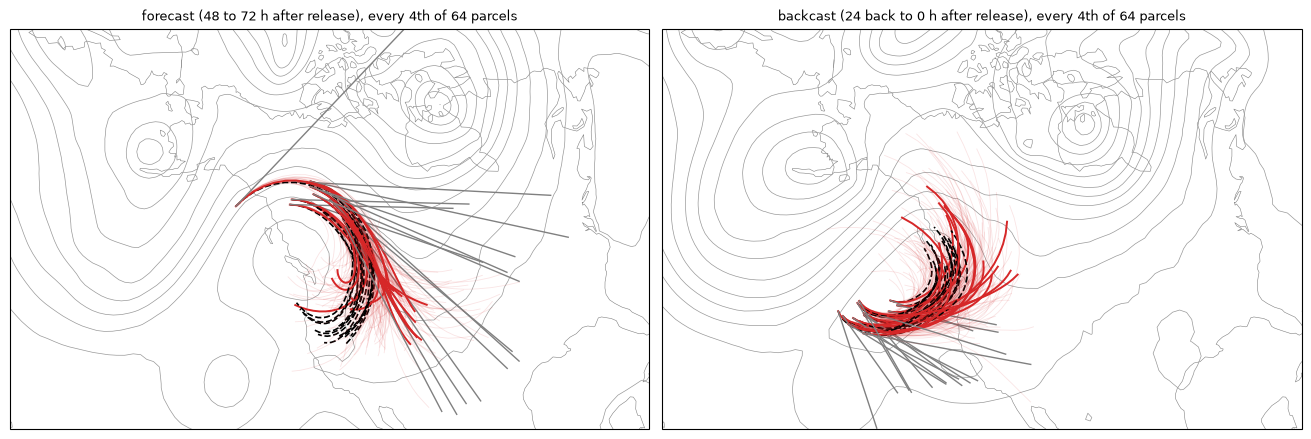

In [10]:
k, q = 1, 0
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout='constrained', subplot_kw=dict(projection=ccrs.NorthPolarStereo(central_longitude=235)))
for ax, (task, d, t0) in zip(axes, (('forecast', 1, 48), ('backcast', -1, 24))):
    tgt, det, ensm = keep[(k, q, task)]
    ax.set_extent([195, 285, 30, 78], ccrs.PlateCarree()); ax.coastlines(lw=0.4, color='0.5')
    ax.contour(z500.longitude, z500.latitude, z500.isel(time=1 if d > 0 else 0), levels=np.arange(5200, 6000, 60), colors='0.6', linewidths=0.5, transform=ccrs.PlateCarree())
    hours = t0 + d * np.arange(25)
    for j in range(0, len(tgt), 4):
        for m in range(ensm.shape[1]):
            lo, la = xy_to_lonlat(ensm[:, m, j]); ax.plot(lo, la, color='tab:red', alpha=0.12, lw=0.6, transform=ccrs.Geodetic())
        for path, sty in ((X[hours, tgt[j]], dict(color='k', ls='--', lw=1.2)), (det[:, j], dict(color='tab:red', lw=1.4)),
                          (X[t0, tgt[j]] + d * np.arange(25)[:, None] * V[t0, tgt[j]], dict(color='0.5', lw=1))):
            lo, la = xy_to_lonlat(path); ax.plot(lo, la, transform=ccrs.Geodetic(), **sty)
    ax.set_title(f'{task} ({"48 to 72" if d > 0 else "24 back to 0"} h after release), every 4th of 64 parcels', fontsize=9)
plt.show()

## 8. Clean up
The downloaded winds (about 34 GB) are deleted; the tracks stay in memory.

In [11]:
shutil.rmtree(WORK)
print('removed', WORK.relative_to(ROOT))

removed data/notebook
